In [1]:
# import library
import os
import keras
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

In [2]:
# Load Dataset

PATH = 'dataset/'
CLASS_NAMES = os.listdir(PATH)
print(CLASS_NAMES)

['Cucumber', 'Broccoli', 'Tomato', 'Carrot']


In [3]:
# Load image
counter = 0
rows, cols = 224, 224
x, y = [],[]

for class_name in CLASS_NAMES:
    for img_name in os.listdir(PATH + class_name):
        path = f"{PATH}{class_name}/{img_name}"
        label = counter
        image = tf.keras.preprocessing.image.load_img(path, target_size=(rows, cols), color_mode='grayscale')
        image = tf.keras.preprocessing.image.img_to_array(image)
        x.append(image)
        y.append(label)
    counter += 1
    print(class_name)
    
x = np.array(x)
y = np.array(y)
x = x.astype('float32') / 255.0

print(x.shape)
print(y.shape)


Cucumber
Broccoli
Tomato
Carrot
(2000, 224, 224, 1)
(2000,)


In [4]:
# splitting
x_train, x_temp, y_train, y_temp = train_test_split(x, y, test_size=0.2, random_state=42, stratify=y)
x_val, x_test, y_val, y_test = train_test_split(x_temp, y_temp, test_size=0.5, random_state=42, stratify=y_temp)

In [5]:
# Preprocessing OHE
y_train = keras.utils.to_categorical(y_train, num_classes=4)
y_val = keras.utils.to_categorical(y_val, num_classes=4)
y_test = keras.utils.to_categorical(y_test, num_classes=4)

In [6]:
# DCNN

model = keras.Sequential([
    keras.layers.Input(shape=(rows, cols, 1)),
    
    keras.layers.Conv2D(8, (5,5), activation="relu"),
    keras.layers.MaxPooling2D(pool_size=(2,2), strides=2),
    keras.layers.Conv2D(16, (5,5), activation="relu"),
    keras.layers.Conv2D(16, (5,5), activation="relu"),
    keras.layers.MaxPooling2D(pool_size=(2,2), strides=2),
    keras.layers.Flatten(),
    
    keras.layers.Dense(120, activation="relu"),
    keras.layers.Dense(4, activation="softmax"),
])

model.summary()

2026-10-11 23:55:40.932901: I metal_plugin/src/device/metal_device.cc:1154] Metal device set to: Apple M1
2026-10-11 23:55:40.933063: I metal_plugin/src/device/metal_device.cc:296] systemMemory: 8.00 GB
2026-10-11 23:55:40.933067: I metal_plugin/src/device/metal_device.cc:313] maxCacheSize: 2.67 GB
2026-10-11 23:55:40.933413: I tensorflow/core/common_runtime/pluggable_device/pluggable_device_factory.cc:305] Could not identify NUMA node of platform GPU ID 0, defaulting to 0. Your kernel may not have been built with NUMA support.
2026-10-11 23:55:40.933427: I tensorflow/core/common_runtime/pluggable_device/pluggable_device_factory.cc:271] Created TensorFlow device (/job:localhost/replica:0/task:0/device:GPU:0 with 0 MB memory) -> physical PluggableDevice (device: 0, name: METAL, pci bus id: <undefined>)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 220, 220, 8)    │           208 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 110, 110, 8)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 106, 106, 16)   │         3,216 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 102, 102, 16)   │         6,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 51, 51, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 41616)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 120)            │     4,994,040 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │           484 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5,004,364 (19.09 MB)

 Trainable params: 5,004,364 (19.09 MB)

 Non-trainable params: 0 (0.00 B)

In [7]:
model.compile(optimizer="adam", loss="categorical_crossentropy", metrics=["accuracy"])
history = model.fit(x_train, y_train, batch_size=32, epochs=10, validation_data=(x_val, y_val))

Epoch 1/10


2026-10-11 23:55:42.205595: I tensorflow/core/grappler/optimizers/custom_graph_optimizer_registry.cc:117] Plugin optimizer for device_type GPU is enabled.


50/50 ━━━━━━━━━━━━━━━━━━━━ 6s 93ms/step - accuracy: 0.4331 - loss: 1.2566 - val_accuracy: 0.6350 - val_loss: 0.8477
Epoch 2/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 5s 100ms/step - accuracy: 0.7269 - loss: 0.7207 - val_accuracy: 0.8000 - val_loss: 0.6294
Epoch 3/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 5s 99ms/step - accuracy: 0.8206 - loss: 0.4926 - val_accuracy: 0.8250 - val_loss: 0.4875
Epoch 4/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 5s 90ms/step - accuracy: 0.8894 - loss: 0.3139 - val_accuracy: 0.8550 - val_loss: 0.4755
Epoch 5/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 4s 86ms/step - accuracy: 0.8888 - loss: 0.2893 - val_accuracy: 0.8400 - val_loss: 0.7006
Epoch 6/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 4s 89ms/step - accuracy: 0.9287 - loss: 0.1937 - val_accuracy: 0.8300 - val_loss: 0.7435
Epoch 7/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 5s 93ms/step - accuracy: 0.9388 - loss: 0.1790 - val_accuracy: 0.8300 - val_loss: 0.9753
Epoch 8/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 5s 92ms/step - accuracy: 0.9444 - loss: 0.1501 - val_accuracy: 0.8450 - val_loss: 1

In [8]:
# Model Evaluate
model.evaluate(x_test, y_test)

7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - accuracy: 0.7850 - loss: 1.8517


[1.8516845703125, 0.7850000262260437]

7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step


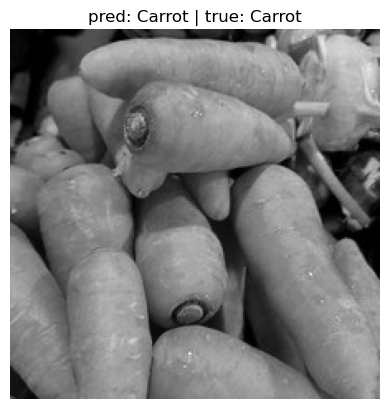

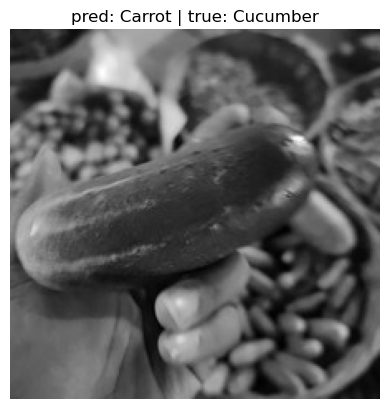

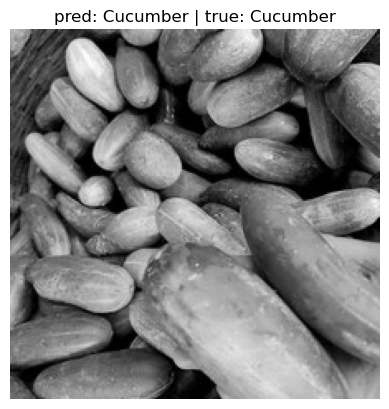

In [9]:
# Model Predict
pred_result = model.predict(x_test)

for i in range(3):
    pred = CLASS_NAMES[np.argmax(pred_result[i])]
    true = CLASS_NAMES[np.argmax(y_test[i])]
    
    plt.imshow(x_test[i].squeeze(), cmap="gray")
    plt.title(f"pred: {pred} | true: {true}")
    plt.axis('off')
    plt.show()

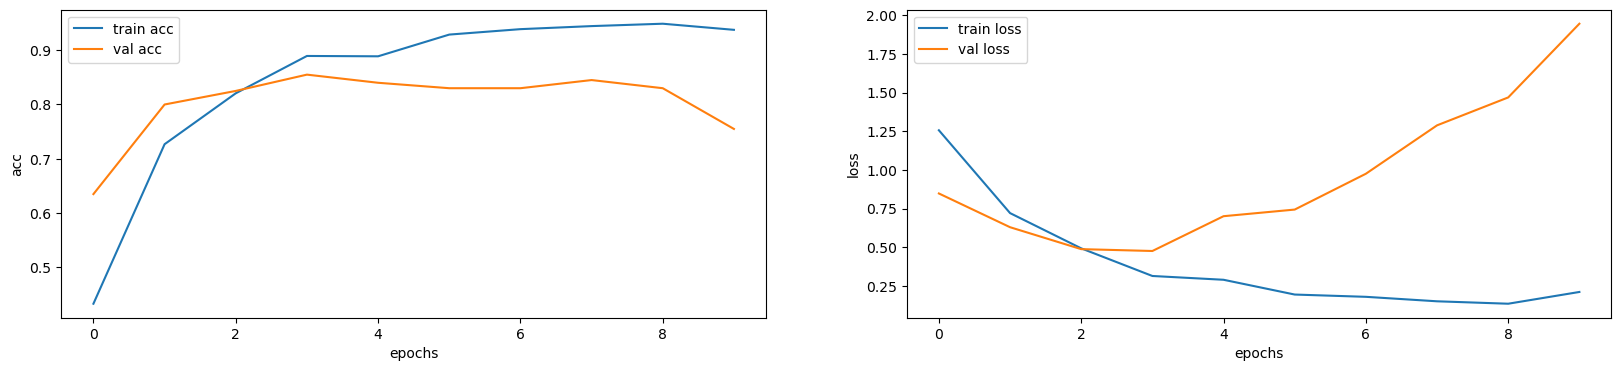

In [10]:
# Plotting
plt.figure(figsize=(20,4))

plt.subplot(1,2,1)
plt.plot(history.history['accuracy'], label="train acc")
plt.plot(history.history['val_accuracy'], label="val acc")
plt.xlabel("epochs")
plt.ylabel("acc")
plt.legend()

plt.subplot(1,2,2)
plt.plot(history.history['loss'], label="train loss")
plt.plot(history.history['val_loss'], label="val loss")
plt.xlabel("epochs")
plt.ylabel("loss")
plt.legend()
plt.show()